# 03 — Extraction de caractéristiques
Module `src/features.py`, appliqué aux images **prétraitées** (configuration du notebook 02).

| Famille | Contenu | Cours |
|---|---|---|
| **histogramme** (par zone) | histogramme normalisé 16 intervalles | Ch. 2 |
| **statistiques** (par zone) | moyenne, écart-type, contraste (max−min)/(max+min) | Ch. 2 |
| **sobel** (par zone) | énergie du gradient (passe-haut) | Ch. 3 |
| **résidu** (par zone, objets) | \|I − I_ref\| moyen et maximal | Ch. 2 (soustraction d'images) |
| **ORB / SIFT sac de mots** (global) | histogramme de 64 mots visuels (K-Means) | Ch. 1 |
| **ORB / SIFT quantification** (global) | distance des descripteurs à leur mot le plus proche | Ch. 1 |
| **ORB / SIFT appariement** (global) | bons appariements avec la référence (test de ratio) | Ch. 1 |

Zones : 32×32 pixels, pas de 16 → **225 zones** qui se chevauchent (hazelnut : 16×16, pas de 8 → **961 zones**, choisi à l'étape 6).  
Prétraitement : normalisation `minmax`, sauf carpet en `localnorm` (éclairage non uniforme, étape 6).

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.data_loader import load_config
from src.features import compute_features

cfg = load_config(ROOT / "config.yaml"); CATS = cfg["data"]["categories"]
OUT = ROOT / "results" / "03_caracteristiques"; OUT.mkdir(parents=True, exist_ok=True)
F, T = {}, {}
for c in CATS:
    t0 = time.time(); F[c] = compute_features(c, cfg); T[c] = time.time() - t0
print({c: f"{t:.0f} s" for c, t in T.items()})

C:\Users\Admin\Desktop\S9\Computer vision\projet_computer_vision\Visual Anomaly Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[cache] features_bottle_8ec0da5b85.joblib


[cache] features_hazelnut_42f86eea78.joblib


[cache] features_carpet_6fb098143f.joblib


{'bottle': '0 s', 'hazelnut': '0 s', 'carpet': '0 s'}


In [2]:
rows = []
for c in CATS:
    d, fx = F[c], F[c]["fx"]
    rows.append({"catégorie": c, "zones / image": d["train"]["zones"].shape[1],
                 "caract. / zone": d["train"]["zones"].shape[2], "caract. globales": d["train"]["global"].shape[1],
                 "familles par zone": ", ".join(fx.zone_families()), "temps total (s)": round(T[c])})
pd.DataFrame(rows).set_index("catégorie")

,zones / image,caract. / zone,caract. globales,familles par zone,temps total (s)
catégorie,,,,,
bottle,225,22,138,"histogramme, statistiques, sobel, residu",0
hazelnut,961,22,138,"histogramme, statistiques, sobel, residu",0
carpet,225,20,138,"histogramme, statistiques, sobel",0


## 1. Visualisation des caractéristiques par zone sur des images défectueuses

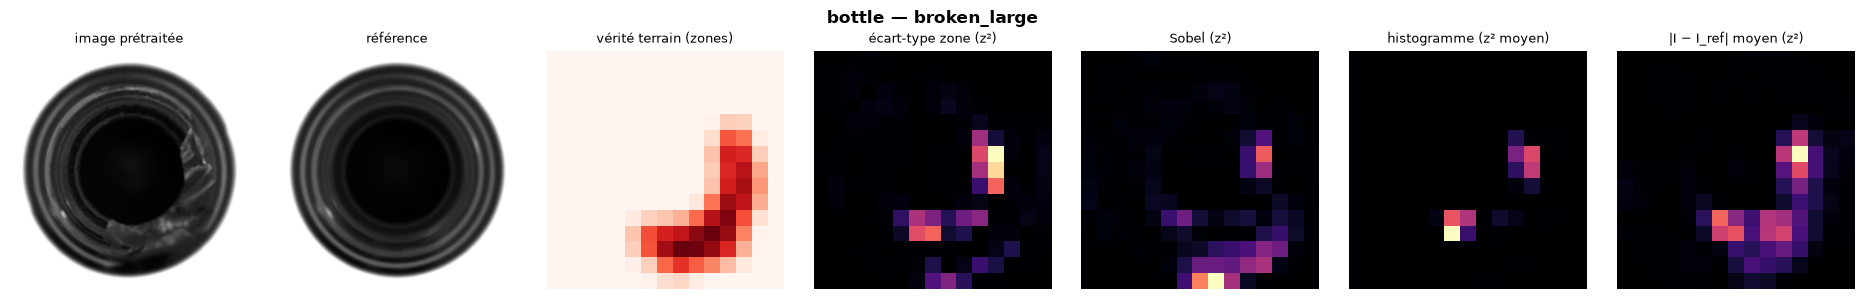

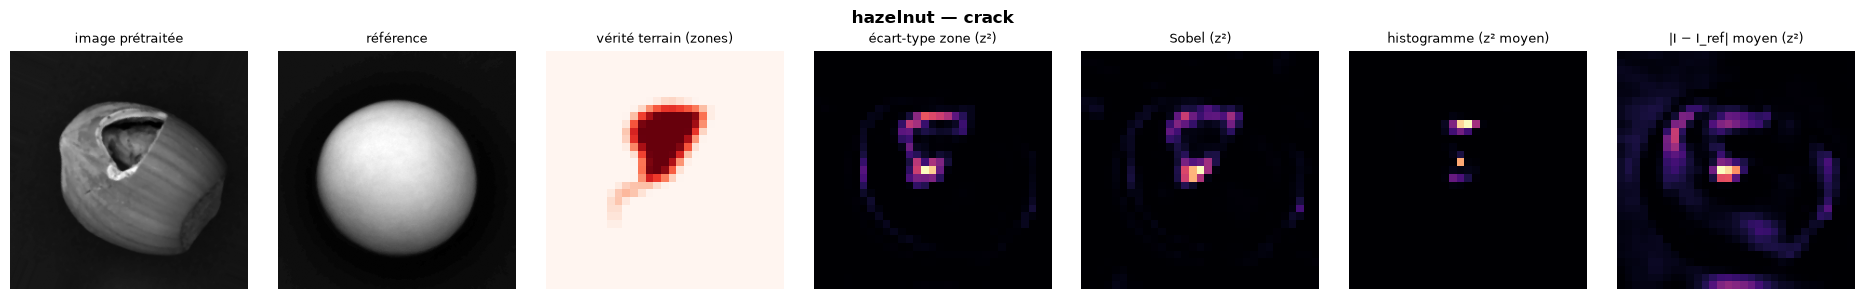

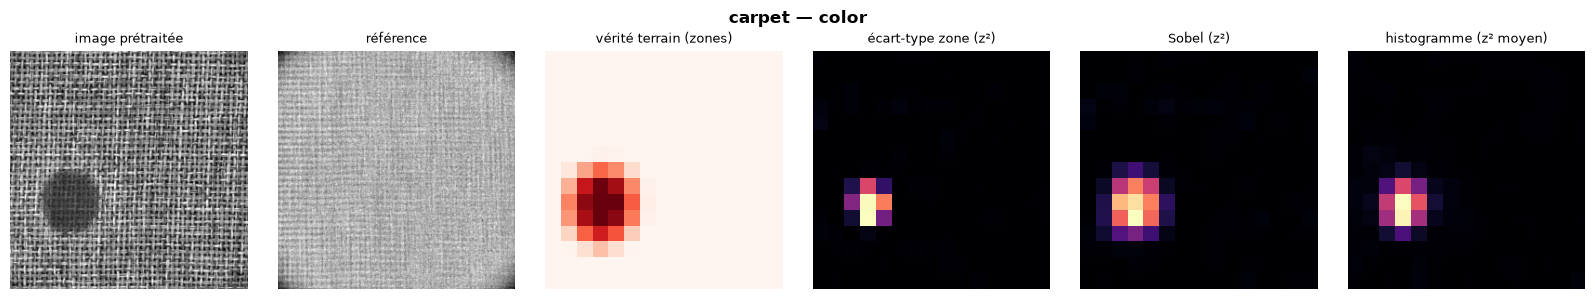

In [3]:
def zmap(v):
    n = int(round(np.sqrt(len(v)))); return v.reshape(n, n)   # 15x15 (zones 32 px) ou 31x31 (16 px)
for c in CATS:
    d = F[c]; te = d["test"]; fx = d["fx"]; names = fx.zone_names()
    i = int(np.argmax(te["zone_truth"].max(1) * (te["labels"] == 1)))   # défaut le plus visible
    Z = te["zones"][i]; Ztr = d["train"]["zones"]
    mu, sd = Ztr.mean(0), Ztr.std(0) + 1e-3
    zsc = ((Z - mu) / sd) ** 2
    panels = [("image prétraitée", te["images"][i], "gray"), ("référence", d["pre"].reference, "gray"),
              ("vérité terrain (zones)", zmap(te["zone_truth"][i]), "Reds"),
              ("écart-type zone (z²)", zmap(zsc[:, names.index("ecart_type")]), "magma"),
              ("Sobel (z²)", zmap(zsc[:, names.index("sobel")]), "magma"),
              ("histogramme (z² moyen)", zmap(zsc[:, :fx.hist_bins].mean(1)), "magma")]
    if "residu_moy" in names:
        panels.append(("|I − I_ref| moyen (z²)", zmap(zsc[:, names.index("residu_moy")]), "magma"))
    fig, axes = plt.subplots(1, len(panels), figsize=(2.7 * len(panels), 3))
    for ax, (t, im, cm) in zip(axes, panels):
        ax.imshow(im, cmap=cm); ax.set_title(t, fontsize=9); ax.axis("off")
    fig.suptitle(f"{c} — {te['defects'][i]}", fontweight="bold"); plt.tight_layout()
    plt.savefig(OUT / f"zones_{c}.png", dpi=110); plt.show()

## 2. Points ORB et SIFT, colorés par erreur de quantification
Rouge = descripteur **loin de tous les mots** du vocabulaire appris sur les images saines (motif inhabituel).

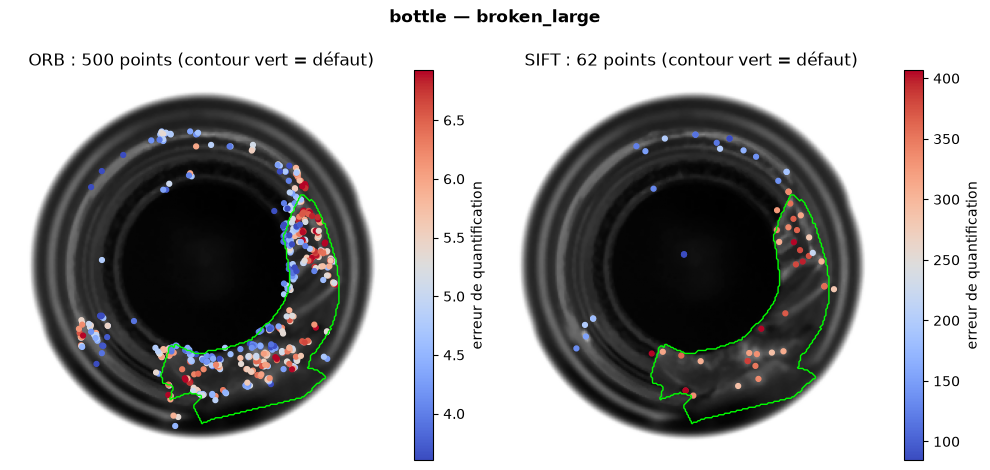

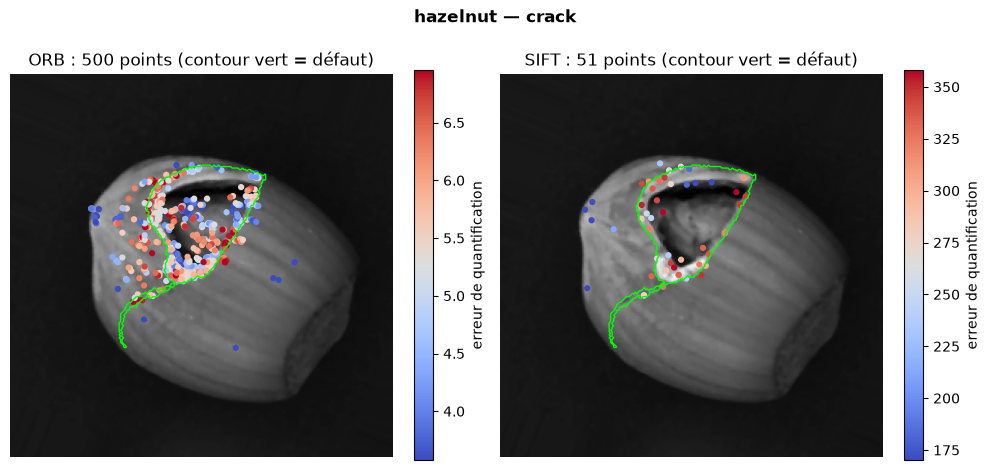

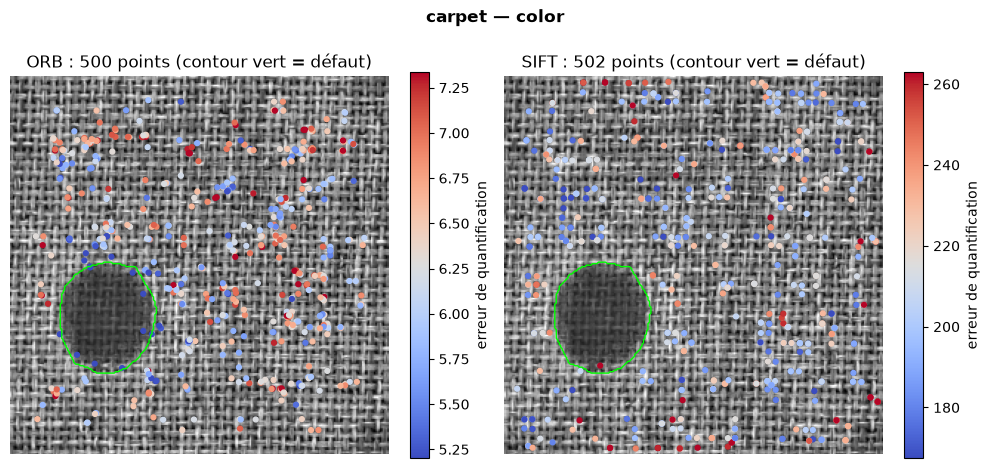

In [4]:
from src.features import _as_float
for c in CATS:
    d = F[c]; te = d["test"]; fx = d["fx"]
    i = int(np.argmax(te["zone_truth"].max(1) * (te["labels"] == 1)))
    img, mask = te["images"][i], te["masks"][i]
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, kind in zip(axes, fx.descriptors):
        bv = fx.bovw[kind]; kp, des = bv.describe(img)
        X = _as_float(des, kind); q = np.linalg.norm(X - bv.kmeans.cluster_centers_[bv.kmeans.predict(X)], axis=1)
        pts = np.array([k.pt for k in kp])
        ax.imshow(img, cmap="gray"); ax.contour(mask, levels=[0.5], colors="lime", linewidths=1)
        sc = ax.scatter(pts[:, 0], pts[:, 1], c=q, cmap="coolwarm", s=12, vmin=np.percentile(q, 5), vmax=np.percentile(q, 95))
        ax.set_title(f"{kind.upper()} : {len(kp)} points (contour vert = défaut)"); ax.axis("off")
        plt.colorbar(sc, ax=ax, fraction=0.046, label="erreur de quantification")
    fig.suptitle(f"{c} — {te['defects'][i]}", fontweight="bold"); plt.tight_layout()
    plt.savefig(OUT / f"orb_sift_{c}.png", dpi=110); plt.show()

## 3. Pouvoir discriminant de chaque famille, **sans modèle** (référence pour l'étape 6)
Test volontairement simple : on standardise chaque caractéristique avec la moyenne et l'écart-type des images saines d'**apprentissage**, puis :
- **par zone** : score de zone = moyenne des z² de la famille ; score d'image = **maximum** sur les 225 zones ;
  - *par position* : moyenne et écart-type calculés **pour chaque position** de zone (suppose un alignement parfait) ;
  - *partagé* : statistiques **communes à toutes les zones** (insensible à la position) ;
- **global** : score d'image = moyenne des z².

On mesure l'AUROC sur le test (0,5 = hasard, 1 = séparation parfaite). Les modèles OC-SVM et Isolation Forest de l'étape 6 devront faire **mieux** que cette base.

In [5]:
def auroc_zone(d, cols, mode):
    Ztr, Zte = d["train"]["zones"][:, :, cols], d["test"]["zones"][:, :, cols]
    if mode == "par position":
        mu, sd = Ztr.mean(0), Ztr.std(0) + 1e-3
    else:
        flat = Ztr.reshape(-1, len(cols)); mu, sd = flat.mean(0), flat.std(0) + 1e-3
    zone_score = (((Zte - mu) / sd) ** 2).mean(-1)
    img = roc_auc_score(d["test"]["labels"], zone_score.max(1))
    zt = d["test"]["zone_truth"]; keep = (zt == 0) | (zt > 0.1)       # zones nettement saines / défectueuses
    loc = roc_auc_score((zt[keep] > 0.1).astype(int), zone_score[keep])
    return img, loc

def auroc_global(d, cols):
    Gtr, Gte = d["train"]["global"][:, cols], d["test"]["global"][:, cols]
    mu, sd = Gtr.mean(0), Gtr.std(0) + 1e-6
    return roc_auc_score(d["test"]["labels"], (((Gte - mu) / sd) ** 2).mean(1))

rows = []
for c in CATS:
    d, fx = F[c], F[c]["fx"]
    fams = dict(fx.zone_families()); fams["toutes (zones)"] = list(range(d["train"]["zones"].shape[2]))
    for fam, cols in fams.items():
        for mode in ("par position", "partagé"):
            a_img, a_loc = auroc_zone(d, cols, mode)
            rows.append({"catégorie": c, "famille": fam, "type": f"zone, {mode}", "AUROC image": a_img, "AUROC zone": a_loc})
    gf = dict(fx.global_families()); gf["toutes (globales)"] = list(range(d["train"]["global"].shape[1]))
    for fam, cols in gf.items():
        rows.append({"catégorie": c, "famille": fam, "type": "global", "AUROC image": auroc_global(d, cols), "AUROC zone": np.nan})
df_auc = pd.DataFrame(rows)
tab = df_auc.pivot_table(index=["type", "famille"], columns="catégorie", values="AUROC image").round(3)[CATS]
tab.to_csv(OUT / "auroc_sans_modele.csv"); tab

catégorie                               bottle  hazelnut  carpet
type               famille                                      
global             orb_appariement       0.770     0.500   0.453
                   orb_quantification    0.711     0.565   0.504
                   orb_sac_de_mots       0.891     0.548   0.543
                   sift_appariement      0.892     0.500   0.500
                   sift_quantification   0.929     0.738   0.541
                   sift_sac_de_mots      0.759     0.672   0.408
                   toutes (globales)     0.899     0.643   0.453
zone, par position histogramme           0.943     0.739   0.887
                   residu                0.986     0.524     NaN
                   sobel                 0.974     0.818   0.825
                   statistiques          0.979     0.704   0.777
                   toutes (zones)        0.954     0.734   0.864
zone, partagé      histogramme           0.402     0.785   0.893
                   residu                0.920     0.864     NaN
                   sobel                 0.422     0.948   0.790
                   statistiques          0.500     0.875   0.760
                   toutes (zones)        0.678     0.853   0.852

In [6]:
tab_loc = df_auc.dropna().pivot_table(index=["type", "famille"], columns="catégorie", values="AUROC zone").round(3)[CATS]
tab_loc.to_csv(OUT / "auroc_localisation_sans_modele.csv"); tab_loc

catégorie                          bottle  hazelnut  carpet
type               famille                                 
zone, par position histogramme      0.857     0.882   0.727
                   residu           0.892     0.785     NaN
                   sobel            0.815     0.883   0.748
                   statistiques     0.873     0.868   0.727
                   toutes (zones)   0.904     0.874   0.764
zone, partagé      histogramme      0.505     0.828   0.727
                   residu           0.803     0.925     NaN
                   sobel            0.381     0.937   0.739
                   statistiques     0.324     0.926   0.723
                   toutes (zones)   0.662     0.946   0.758

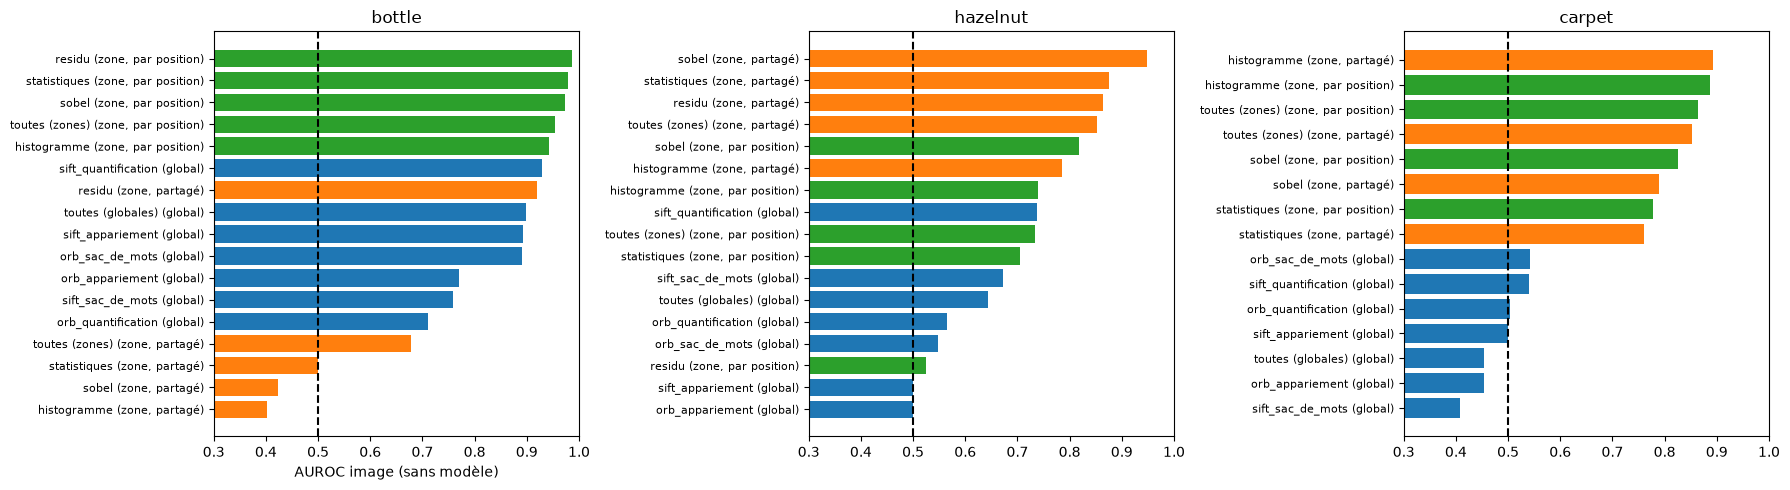

In [7]:
fig, axes = plt.subplots(1, len(CATS), figsize=(6 * len(CATS), 5), sharex=True)
for ax, c in zip(axes, CATS):
    sub = df_auc[df_auc["catégorie"] == c].copy(); sub["nom"] = sub["famille"] + " (" + sub["type"] + ")"
    sub = sub.sort_values("AUROC image")
    colors = ["tab:blue" if "global" in t else ("tab:orange" if "partagé" in t else "tab:green") for t in sub["type"]]
    ax.barh(sub["nom"], sub["AUROC image"], color=colors); ax.axvline(0.5, color="k", ls="--")
    ax.set_xlim(0.3, 1); ax.set_title(c); ax.tick_params(axis="y", labelsize=8)
axes[0].set_xlabel("AUROC image (sans modèle)")
plt.tight_layout(); plt.savefig(OUT / "auroc_sans_modele.png", dpi=110); plt.show()

## Conclusions (prétraitement final de l'étape 8)

**AUROC image sans modèle : meilleure famille par catégorie** (choisie *a posteriori* sur le test, donc à titre indicatif)

| | meilleure famille | AUROC | remarque |
|---|---|---|---|
| **bottle** | résidu \|I−I_ref\|, par position | **0,986** | les familles par position dépassent 0,94 ; ORB/SIFT global entre 0,71 et 0,93 |
| **hazelnut** (zones 16 px, sans normalisation) | Sobel, **partagé** | **0,948** | le résidu par position ne vaut que 0,52, contre 0,86 en partagé |
| **carpet** (`localnorm`, sans médian) | histogramme, partagé | 0,893 | ORB/SIFT global toujours **inversé ou nul** (0,41 à 0,54) |

**Constats :**
1. **bottle** est bien aligné : comparer chaque zone à la même zone des images saines (par position) fonctionne presque parfaitement. Le résidu (soustraction d'images, Ch. 2) est la meilleure caractéristique.
2. **hazelnut** : comme l'alignement des noix est imparfait, les statistiques **partagées** entre les zones sont bien meilleures que les statistiques par position. Le Sobel partagé atteint 0,948 : il y a donc beaucoup d'information dans les caractéristiques, plus que ce que le détecteur final exploite (étape 6).
3. **carpet** : sur une texture, l'**histogramme** d'intensité par zone est la meilleure famille. Les caractéristiques globales ORB/SIFT ne fonctionnent pas sur cette texture.
4. La **localisation** fonctionne : l'AUROC par zone va de 0,72 à 0,95.
5. Ces valeurs choisissent la meilleure famille **en regardant le test**. Elles servent de repère et ne sont pas comparables directement aux détecteurs, qui sont choisis **sans** vrai défaut.